rho = 0.815, f_ret = 0.733, Top-45 thr = 13.259, gray above line = 45.0 (target 45), gray total(>13) = 94


/var/folders/x0/h_lnpc2s7tj88s2gg8lg03l80000gn/T/ipykernel_49033/963497638.py:149: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  ax = fig.add_subplot(grid[0, 0])
/var/folders/x0/h_lnpc2s7tj88s2gg8lg03l80000gn/T/ipykernel_49033/963497638.py:155: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  middle = fig.add_subplot(grid[0, 1], sharey=ax)
/var/folders/x0/h_lnpc2s7tj88s2gg8lg03l80000gn/T/ipykernel_49033/963497638.py:163: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  right = fig.add_subplot(grid[0, 2], sharey=ax)
/var/folders/x0/h_lnpc2s7tj88s2gg8lg03l80000gn/T/ipykernel_49033/963497638.py:174: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  ax = fig.add_subplot(grid[1, 0])
/var/folders/x0/h_lnpc2s7tj88s2gg8lg03l80000gn/T/ipykernel_49033/963497638.py:192: UserWarn

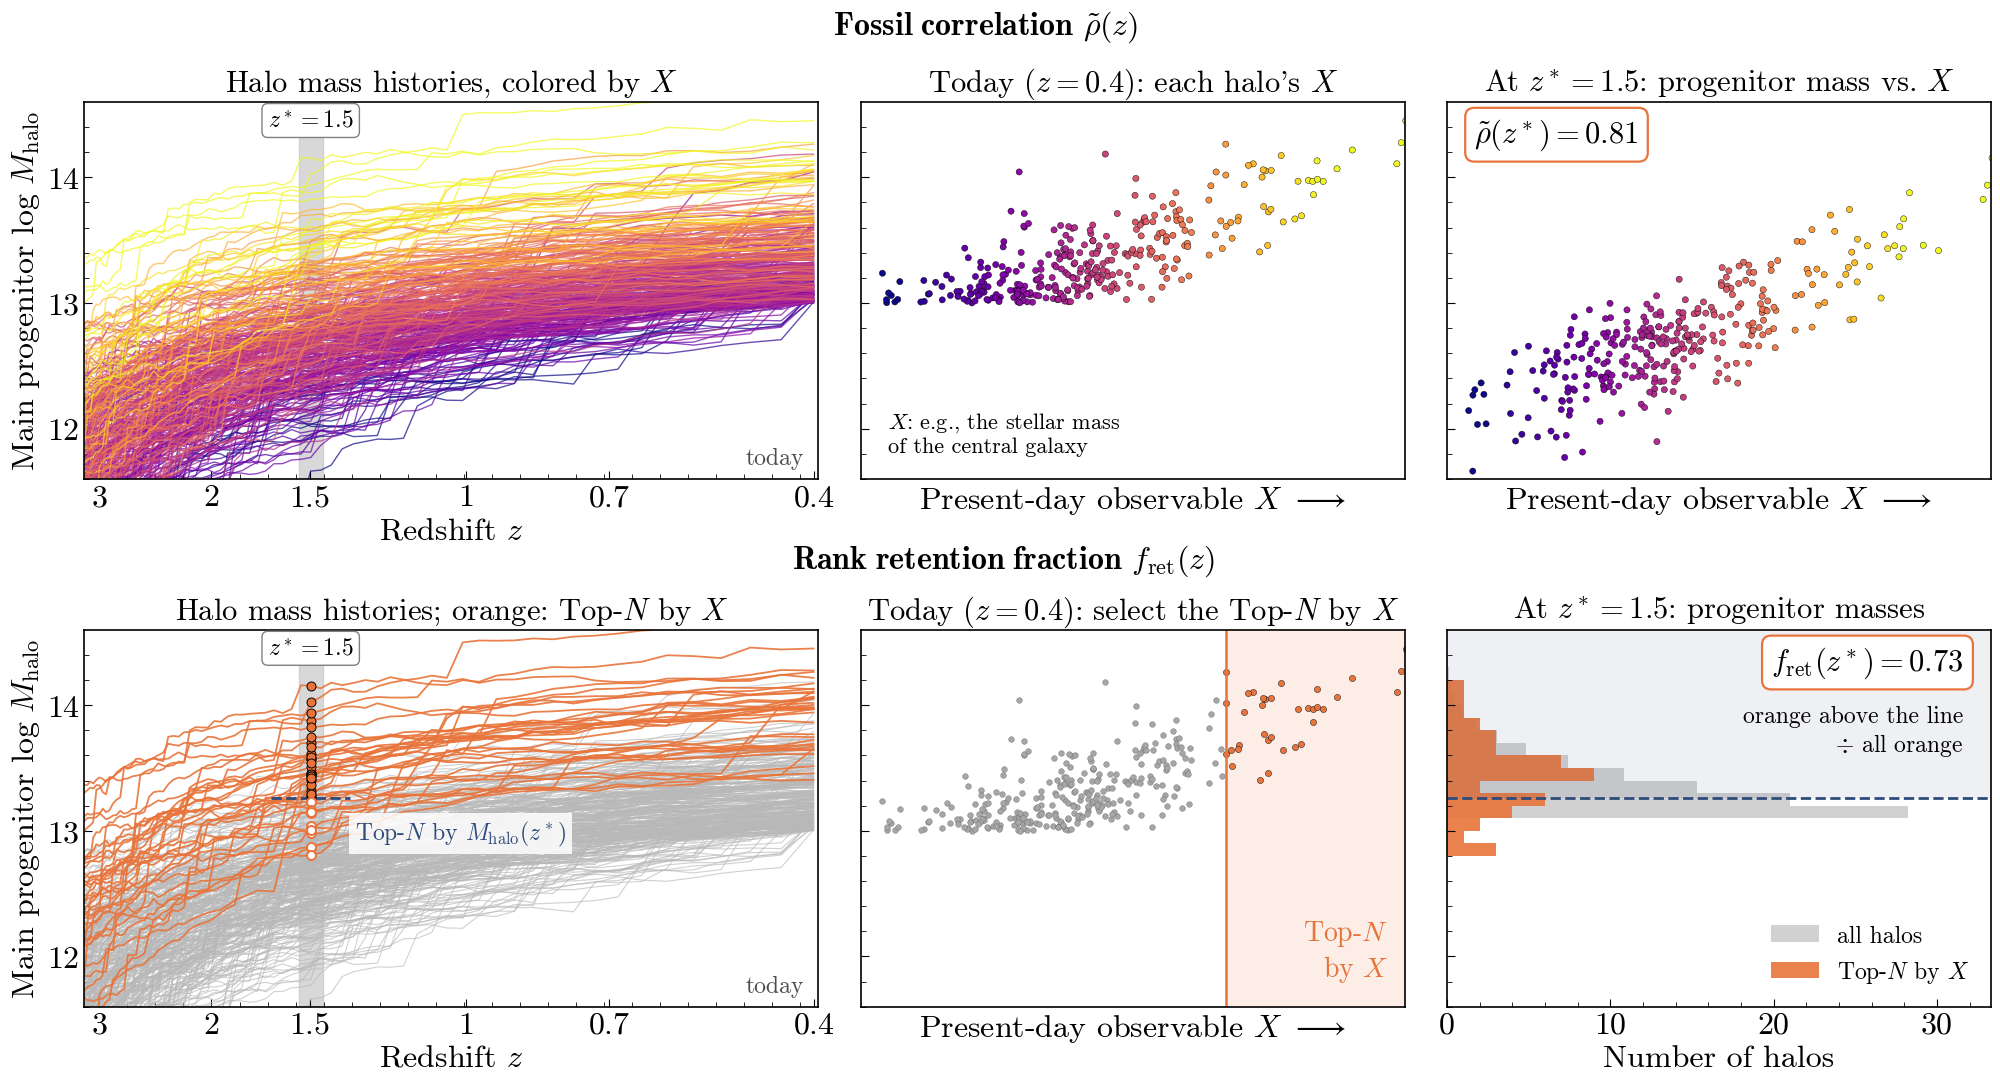

In [22]:
# Illustration Figure 1: fossil correlation rho~(z) and rank retention fraction f_ret(z)
# Structure and drawing style follow fig1_concept.py (real-TNG300 version); since the
# TNG300 npz is not available here, mass histories are mock but mimic real merger trees
# (stochastic increments + merger jumps, non-monotonic). Today cut: log M_halo > 13.0 at
# z = 0.4, masses drawn from the Tinker08 HMF. Gray reference in the bottom-right panel:
# Tinker et al. (2008) HMF expected counts at z* = 1.5, same bin width as the orange
# histogram, volume normalized so the gray count at the dashed-line bin matches the
# orange count there.
import numpy as np
from scipy import integrate
from scipy.interpolate import CubicSpline
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

orange, navy = "#e8743b", "#2f4b7c"

# ---------------- cosmology & Tinker08 HMF (Planck15) ----------------
Om, Ob, h, ns, s8 = 0.307, 0.0486, 0.677, 0.967, 0.816
rho_m = 2.775e11 * Om * h**2

def growth_D(z):
    a = 1.0/(1.0+z); Oma = Om*(1+z)**3/(Om*(1+z)**3 + 1-Om); Ola = 1.0-Oma
    return a*2.5*Oma/(Oma**(4/7) - Ola + (1+Oma/2)*(1+Ola/70))
D0 = growth_D(0.0)

def transfer_EH(k):                       # Eisenstein & Hu 1998, k in h/Mpc
    Omh2, Obh2 = Om*h**2, Ob*h**2; fb = Ob/Om
    s = 44.5*np.log(9.83/Omh2)/np.sqrt(1+10*Obh2**0.75); s_h = s/h
    al = 1 - 0.328*np.log(431*Omh2)*fb + 0.38*np.log(22.3*Omh2)*fb**2
    Geff = Om*h*(al + (1-al)/(1+(0.43*k*s_h)**4)); q = k/Geff
    L0 = np.log(2*np.e + 1.8*q); C0 = 14.2 + 731/(1+62.5*q)
    return L0/(L0 + C0*q**2)

_k = np.logspace(-4, 2, 4000); _Pk = _k**ns * transfer_EH(_k)**2
_R = np.logspace(-1.5, 2.2, 400)
_x = _k[:, None]*_R[None, :]
_W = np.where(np.abs(_x) < 1e-3, 1/3 - _x**2/30.0, (np.sin(_x)-_x*np.cos(_x))/_x**3)
_sig = np.sqrt(integrate.trapezoid((_k**3/(2*np.pi**2))[:, None]*_Pk[:, None]*_W**2, _k, axis=0))
_sig *= s8/np.interp(8.0, _R, _sig)
_lgs = CubicSpline(np.log(_R), np.log(_sig))

def hmf_dndlogM(lgM, z):                  # Tinker08, Delta=200; per Mpc^3 per dex
    M = 10**np.atleast_1d(np.asarray(lgM, float))
    R = (3*M/(4*np.pi*rho_m))**(1/3)*h
    sig = np.exp(_lgs(np.log(R)))*growth_D(z)/D0
    A0, a0, b0, c0 = 0.186, 1.47, 2.57, 1.19
    ae = 10**(-(0.75/np.log10(200/75.0))**1.2)
    A = A0*(1+z)**-0.14; a = a0*(1+z)**-0.06; b = b0*(1+z)**-ae
    f = A*((sig/b)**-a + 1)*np.exp(-c0/sig**2)
    return (f*rho_m/M*(-_lgs(np.log(R), 1)/3)*np.log(10)).squeeze()

# cosmic time (Gyr), for the time axis with redshift tick labels
H0 = 67.7
_zz = np.linspace(0, 8, 4000)
_Hz = H0*np.sqrt(Om*(1+_zz)**3 + 1-Om)
_lookback = 977.8*integrate.cumulative_trapezoid(1/((1+_zz)*_Hz), _zz, initial=0)
def t_of_z(z): return _lookback[-1] - np.interp(z, _zz, _lookback)

# ---------------- mock sample: stochastic merger-tree-like histories ----------------
Z0, SLICE_Z = 0.4, 1.5
N_HALO, NTOP, SEED, XSCATTER = 450, 45, 1, 0.46
zsnaps = np.linspace(3.2, Z0, 70)
times = t_of_z(zsnaps)
dzb = zsnaps[:-1] - zsnaps[1:]            # > 0 going backward in time
i_star = int(np.argmin(np.abs(zsnaps - SLICE_Z)))
i_z1 = int(np.argmin(np.abs(zsnaps - 1.0)))   # X reference epoch, as in the original code

def sample_today_masses(N, rng):          # today masses from the z = 0.4 HMF above 1e13
    lgM = np.linspace(13.0, 15.3, 3000)
    pdf = hmf_dndlogM(lgM, Z0); cdf = np.cumsum(pdf); cdf /= cdf[-1]
    return np.interp(rng.random(N), cdf, lgM)

rng = np.random.default_rng(SEED)
lgM0 = sample_today_masses(N_HALO, rng)
alpha = np.clip(rng.normal(0.80, 0.18, N_HALO), 0.3, 1.5)   # per-halo growth rate
eps = rng.normal(size=(N_HALO, len(dzb)))
merg = (rng.random((N_HALO, len(dzb))) < 0.05)*rng.uniform(0.08, 0.30, (N_HALO, len(dzb)))
step = alpha[:, None]*np.log10(np.e)*dzb[None, :] + 0.10*np.sqrt(dzb)[None, :]*eps + merg
drops = np.hstack([np.cumsum(step[:, ::-1], axis=1)[:, ::-1], np.zeros((N_HALO, 1))])
history = lgM0[:, None] - drops           # log10 M200c history, jagged like real trees

reference = history[:, i_z1]
observable = (reference - reference.mean())/reference.std() + XSCATTER*rng.standard_normal(N_HALO)
selected = np.zeros(N_HALO, bool); selected[np.argsort(observable)[-NTOP:]] = True
x_cut = np.sort(observable)[-NTOP]
mass_slice, mass_today = history[:, i_star], history[:, -1]
threshold = np.sort(mass_slice)[-NTOP]
rho = np.corrcoef(observable, mass_slice)[0, 1]
f_ret = np.mean(mass_slice[selected] >= threshold)
show = rng.choice(N_HALO, 330, replace=False)

# gray reference: Tinker08 HMF expected counts, same bins as orange, volume normalized
# so the gray counts ABOVE the dashed line sum to NTOP (the line is then exactly the
# Top-N mass boundary of the HMF population at z*)
bins = np.arange(11.6, 14.65, 0.10)
BINW = bins[1] - bins[0]
_lg = np.linspace(threshold, 15.8, 3000)
gbins = bins[bins >= 13.0]                # gray shown above log M = 13.0
gcents = 0.5*(gbins[:-1] + gbins[1:])
# normalize on the displayed bins: gray counts above the dashed line sum to NTOP
_unit = hmf_dndlogM(gcents, SLICE_Z)*BINW
V_disp = NTOP/_unit[gcents > threshold].sum()
gray_counts = _unit*V_disp
ocnt, _ = np.histogram(mass_slice[selected], bins=bins)
print(f'rho = {rho:.3f}, f_ret = {f_ret:.3f}, Top-{NTOP} thr = {threshold:.3f}, '
      f'gray above line = {gray_counts[gcents > threshold].sum():.1f} (target {NTOP}), '
      f'gray total(>13) = {gray_counts.sum():.0f}')

# ---------------- figure ----------------
redshift_ticks = [3, 2, 1.5, 1, 0.7, 0.4]
tick_times = [t_of_z(z) for z in redshift_ticks]
ylim = (11.6, 14.6)
xlim_observable = np.percentile(observable, [0.5, 99.5])

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['cmr10', 'STIXGeneral'],
    'mathtext.fontset': 'cm', 'font.size': 23,
    'axes.linewidth': 1.2, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3.5, 'ytick.minor.size': 3.5,
})
fig = plt.figure(figsize=(20.5, 11.6))
grid = GridSpec(2, 3, figure=fig, width_ratios=[1.35, 1, 1], wspace=0.07, hspace=0.4,
                left=0.055, right=0.985, top=0.86, bottom=0.08)
cmap = plt.get_cmap('plasma')
norm = plt.Normalize(*np.percentile(observable, [2, 98]))

def history_panel(ax):
    ax.axvspan(times[i_star]-0.12, times[i_star]+0.12, color='0.75', alpha=0.6, zorder=0)
    ax.text(times[i_star], ylim[1]-0.06, r'$z^* = 1.5$', ha='center', va='top', fontsize=17,
            bbox=dict(fc='white', ec='0.5', boxstyle='round,pad=0.25'))
    ax.set_xticks(tick_times, [f'${z:g}$' for z in redshift_ticks])
    ax.text(times[-1]-0.10, ylim[0]+0.08, 'today', ha='right', va='bottom', fontsize=17, color='0.3')
    ax.set(xlim=(times[0], times[-1]+0.05), ylim=ylim, xlabel=r'Redshift $z$',
           ylabel=r'Main progenitor $\log\,M_{\rm halo}$')
    ax.minorticks_on()

def observable_axis(ax, label):
    ax.set(xlim=xlim_observable, xticks=[], xlabel=label)
    ax.tick_params(labelleft=False)

def boxed(ax, x, y, text, ha='left'):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va='top', fontsize=22,
            bbox=dict(fc='white', ec=orange, lw=1.6, boxstyle='round,pad=0.3'))

# ---- Row 1: fossil correlation ----
ax = fig.add_subplot(grid[0, 0])
history_panel(ax)
for i in show[np.argsort(observable[show])]:
    ax.plot(times, history[i], color=cmap(norm(observable[i])), lw=1.0, alpha=0.7)
ax.set_title(r'Halo mass histories, colored by $X$', fontsize=22, pad=8)

middle = fig.add_subplot(grid[0, 1], sharey=ax)
middle.scatter(observable[show], mass_today[show], c=observable[show], cmap=cmap, norm=norm,
               s=20, edgecolor='k', lw=0.3)
observable_axis(middle, r'Present-day observable $X$ $\longrightarrow$')
middle.set_title(r"Today ($z = 0.4$): each halo's $X$", fontsize=22, pad=8)
middle.text(0.05, 0.06, '$X$: e.g., the stellar mass\nof the central galaxy',
            transform=middle.transAxes, fontsize=16, va='bottom')

right = fig.add_subplot(grid[0, 2], sharey=ax)
right.scatter(observable[show], mass_slice[show], c=observable[show], cmap=cmap, norm=norm,
              s=20, edgecolor='k', lw=0.3)
observable_axis(right, r'Present-day observable $X$ $\longrightarrow$')
right.set_title(r'At $z^* = 1.5$: progenitor mass vs. $X$', fontsize=22, pad=8)
boxed(right, 0.05, 0.96, r'$\tilde{\rho}(z^*) = 0.81$')
fig.text(0.42, 0.94,
         r"$\bf{Fossil\ correlation}$ $\tilde{\rho}(z)$",
         fontsize=23, va='top')

# ---- Row 2: rank retention fraction ----
ax = fig.add_subplot(grid[1, 0])
history_panel(ax)
rest, picked = show[~selected[show]], show[selected[show]]
for i in rest:
    ax.plot(times, history[i], color='0.72', lw=0.8, alpha=0.65)
for i in picked:
    ax.plot(times, history[i], color=orange, lw=1.3, alpha=0.9)
above = mass_slice[picked] >= threshold
ax.plot([times[i_star]-0.4, times[i_star]+0.4], [threshold, threshold],
        color=navy, lw=2.0, ls='--', zorder=6)
ax.scatter(np.full(above.sum(), times[i_star]), mass_slice[picked][above],
           s=42, color=orange, edgecolor='k', lw=0.7, zorder=7)
ax.scatter(np.full((~above).sum(), times[i_star]), mass_slice[picked][~above],
           s=42, facecolor='white', edgecolor=orange, lw=1.4, zorder=7)
ax.text(times[i_star]+0.45, threshold-0.28, r'Top-$N$ by $M_{\rm halo}(z^*)$', color=navy,
        fontsize=17, va='center', ha='left', bbox=dict(fc='white', ec='none', alpha=0.85))
ax.set_title(r'Halo mass histories; orange: Top-$N$ by $X$', fontsize=22, pad=8)

middle = fig.add_subplot(grid[1, 1], sharey=ax)
middle.axvspan(x_cut, xlim_observable[1], color=orange, alpha=0.12, lw=0)
middle.axvline(x_cut, color=orange, lw=1.8)
middle.scatter(observable[rest], mass_today[rest], s=17, color='0.65', edgecolor='0.4', lw=0.25)
middle.scatter(observable[picked], mass_today[picked], s=20, color=orange, edgecolor='k', lw=0.3)
observable_axis(middle, r'Present-day observable $X$ $\longrightarrow$')
middle.set_title(r'Today ($z = 0.4$): select the Top-$N$ by $X$', fontsize=22, pad=8)
middle.text(0.97, 0.06, 'Top-$N$\nby $X$', transform=middle.transAxes, ha='right', va='bottom',
            fontsize=20, color=orange)

right = fig.add_subplot(grid[1, 2], sharey=ax)
right.barh(gcents, gray_counts, height=BINW, color='0.82', lw=0)
right.hist(mass_slice[selected], bins=bins, orientation='horizontal', color=orange,
           alpha=0.9, lw=0)
right.axhline(threshold, color=navy, lw=2.0, ls='--')
right.axhspan(threshold, ylim[1], color=navy, alpha=0.08, lw=0)
right.set(xlabel='Number of halos', xlim=(0, gray_counts.max()*1.18))
right.tick_params(labelleft=False)
right.minorticks_on()
right.set_title(r'At $z^* = 1.5$: progenitor masses', fontsize=22, pad=8)
right.legend(handles=[Patch(fc='0.82', label='all halos'),
                      Patch(fc=orange, alpha=0.9, label=r'Top-$N$ by $X$')],
             loc='lower right', frameon=False, fontsize=17)
boxed(right, 0.95, 0.96, r'$f_{\rm ret}(z^*) = 0.73$', ha='right')
right.text(0.95, 0.80, 'orange above the line\n$\\div$ all orange', transform=right.transAxes,
           ha='right', va='top', fontsize=17)
fig.text(0.4, 0.48,
         r'$\bf{Rank\ retention\ fraction}$ $f_{\rm ret}(z)$',
         fontsize=23, va='top')
fig_dir="/Users/xushuo/work/Papers/HistoricRichness/Figure/"
plt.savefig(fig_dir + 'Fig1.pdf', dpi=100, bbox_inches='tight')
